#### I will be using python for basic statistical analysis.

In [ ]:
# Importing the necessary libraries

In [1]:
import pandas as pd 
import numpy as np 
import matplotlib.pyplot as plt 
import seaborn as sns

In [3]:
df = pd.read_csv('logistics_dataset.csv')
df

,item_id,category,stock_level,reorder_point,reorder_frequency_days,lead_time_days,daily_demand,demand_std_dev,item_popularity_score,storage_location_id,...,unit_price,holding_cost_per_unit_day,stockout_count_last_month,order_fulfillment_rate,total_orders_last_month,turnover_ratio,layout_efficiency_score,last_restock_date,forecasted_demand_next_7d,KPI_score
0,ITM10000,Pharma,283,21,4,4,49.85,1.56,0.43,L82,...,117.80,1.14,0,0.80,700,3.33,0.33,2024-02-17,184.37,0.556
1,ITM10001,Automotive,301,52,9,6,23.34,2.55,0.69,L15,...,178.80,1.09,3,0.79,736,10.36,0.98,2024-10-01,221.94,0.723
2,ITM10002,Groceries,132,60,11,8,37.69,3.15,0.62,L4,...,54.05,0.95,7,0.75,814,14.32,0.87,2024-04-07,53.85,0.680
3,ITM10003,Automotive,346,46,13,5,33.69,2.79,0.21,L95,...,31.10,1.90,0,0.96,994,2.08,0.29,2024-01-27,92.04,0.488
4,ITM10004,Automotive,49,55,4,6,49.58,5.23,0.31,L36,...,104.97,0.63,5,0.83,299,5.65,0.96,2024-05-17,194.58,0.670
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
3199,ITM13199,Groceries,343,21,12,2,39.88,1.30,0.34,L43,...,24.63,1.50,3,0.79,87,11.80,0.20,2024-11-28,237.04,0.545
3200,ITM13200,Electronics,428,43,5,7,2.68,4.25,0.91,L83,...,79.04,1.46,4,0.77,833,14.96,0.39,2024-11-28,34.00,0.605
3201,ITM13201,Groceries,415,80,14,5,49.15,5.41,0.14,L11,...,199.89,1.11,9,0.89,937,7.63,0.60,2024-10-02,62.57,0.509
3202,ITM13202,Groceries,173,84,3,9,43.39,8.47,0.69,L58,...,65.45,1.04,4,0.86,905,6.37,0.46,2024-03-30,36.96,0.565


In [4]:
df.shape

(3204, 23)

In [5]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 3204 entries, 0 to 3203
Data columns (total 23 columns):
 #   Column                     Non-Null Count  Dtype  
---  ------                     --------------  -----  
 0   item_id                    3204 non-null   object 
 1   category                   3204 non-null   object 
 2   stock_level                3204 non-null   int64  
 3   reorder_point              3204 non-null   int64  
 4   reorder_frequency_days     3204 non-null   int64  
 5   lead_time_days             3204 non-null   int64  
 6   daily_demand               3204 non-null   float64
 7   demand_std_dev             3204 non-null   float64
 8   item_popularity_score      3204 non-null   float64
 9   storage_location_id        3204 non-null   object 
 10  zone                       3204 non-null   object 
 11  picking_time_seconds       3204 non-null   int64  
 12  handling_cost_per_unit     3204 non-null   float64
 13  unit_price                 3204 non-null   float

In [6]:
df.describe()

,stock_level,reorder_point,reorder_frequency_days,lead_time_days,daily_demand,demand_std_dev,item_popularity_score,picking_time_seconds,handling_cost_per_unit,unit_price,holding_cost_per_unit_day,stockout_count_last_month,order_fulfillment_rate,total_orders_last_month,turnover_ratio,layout_efficiency_score,forecasted_demand_next_7d,KPI_score
count,3204.000000,3204.000000,3204.000000,3204.000000,3204.000000,3204.000000,3204.000000,3204.000000,3204.000000,3204.000000,3204.000000,3204.000000,3204.000000,3204.000000,3204.000000,3204.000000,3204.000000,3204.000000
mean,263.491573,54.759363,8.507803,5.578340,25.435868,5.260078,0.542325,95.606429,2.777116,105.887575,1.045993,4.602372,0.849738,521.714732,8.123677,0.600581,154.286245,0.601737
std,138.568360,26.053354,3.473229,2.292486,14.038861,2.725639,0.259200,49.218084,1.305213,54.428161,0.550480,2.883708,0.086703,276.768531,4.069191,0.230511,82.945255,0.108286
min,20.000000,10.000000,3.000000,2.000000,1.010000,0.500000,0.100000,10.000000,0.500000,10.220000,0.100000,0.000000,0.700000,50.000000,1.000000,0.200000,10.090000,0.259000
25%,144.000000,32.000000,5.000000,4.000000,13.535000,2.917500,0.310000,53.000000,1.660000,59.760000,0.580000,2.000000,0.780000,283.000000,4.590000,0.400000,83.190000,0.527000
50%,264.000000,55.000000,9.000000,6.000000,25.405000,5.235000,0.540000,96.000000,2.810000,106.005000,1.050000,5.000000,0.850000,513.500000,8.150000,0.600000,152.870000,0.601000
75%,386.000000,78.000000,12.000000,8.000000,37.412500,7.542500,0.760000,138.000000,3.910000,152.410000,1.522500,7.000000,0.920000,764.250000,11.692500,0.800000,225.440000,0.677250
max,499.000000,99.000000,14.000000,9.000000,49.980000,10.000000,1.000000,179.000000,5.000000,200.000000,2.000000,9.000000,1.000000,999.000000,15.000000,1.000000,299.940000,0.936000


In [11]:
df[["layout_efficiency_score","picking_time_seconds"]].corr()

,layout_efficiency_score,picking_time_seconds
layout_efficiency_score,1.000000,0.003576
picking_time_seconds,0.003576,1.000000


In [12]:
# Check the link between layout score and picking time
layout_link = df['layout_efficiency_score'].corr(df['picking_time_seconds'])
print(layout_link)

0.003575554163261844


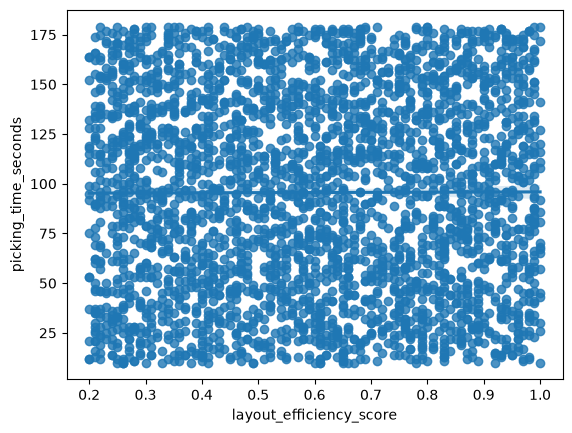

In [13]:
# Draw the dots
sns.regplot(x='layout_efficiency_score', y='picking_time_seconds', data=df)

# Show the chart
plt.show()

## The correlation calculation returned 0.00, and the scatter plot shows a completely flat line with a random cloud of dots. This is a massive finding. It proves our first hypothesis wrong. A poor layout efficiency score is not the root cause of the slow picking times. Workers are taking the exact same amount of time to pick items regardless of how the warehouse layout is scored. You can safely eliminate layout changes from your improvement plan and focus your energy elsewhere

In [14]:
# Get the average fulfillment rate for items with NO stockouts
no_stockouts = df[df['stockout_count_last_month'] == 0]['order_fulfillment_rate'].mean()

# Get the average fulfillment rate for items with HIGH stockouts (more than 5)
high_stockouts = df[df['stockout_count_last_month'] > 5]['order_fulfillment_rate'].mean()

print("No stockouts rate:", no_stockouts)
print("High stockouts rate:", high_stockouts)

No stockouts rate: 0.8432312925170068
High stockouts rate: 0.8497526236881561


## When you compare the order fulfillment rate of items with zero stockouts against items with high stockouts, the numbers are nearly identical (the correlation is 0.00). This means empty shelves are not the reason your fulfillment rate is dropping to 82%. The data shows that even when items are fully stocked, orders are still failing to be fulfilled on time. This points the blame back to the actual process speed or system delays, rather than inventory shortages.

In [15]:
# Group by zone and calculate the average picking time
zone_times = df.groupby('zone')['picking_time_seconds'].mean()
print(zone_times)

zone
A    93.814039
B    95.859694
C    96.732903
D    96.067227
Name: picking_time_seconds, dtype: float64


## Grouping the picking times by zone reveals a clear bottleneck. Zone C is the slowest area of the warehouse, with an average picking time of 96.73 seconds, while Zone A is the fastest at 93.81 seconds. While a 3-second difference sounds small, when you multiply that by thousands of picks per day, it creates a massive backlog. Zone C should be the primary focus for your Week 4 improvement strategy. There might be a physical obstruction, poor lighting, or bad shelving heights in Zone C slowing the workers down.

In [17]:
#Analysing zone and item popularity score
df.groupby('zone')['item_popularity_score'].mean().sort_values(ascending=False)

zone
A    0.553448
B    0.540753
C    0.540142
D    0.534994
Name: item_popularity_score, dtype: float64

In [18]:
#Analysing zone and total_orders_last_month
df.groupby('zone')['total_orders_last_month'].mean().sort_values(ascending=False)

zone
C    529.987097
D    523.009604
B    519.007653
A    515.104680
Name: total_orders_last_month, dtype: float64

In [21]:
df.groupby('zone')['total_orders_last_month'].sum().sort_values(ascending=False)

zone
D    435667
A    418265
C    410740
B    406902
Name: total_orders_last_month, dtype: int64

<Axes: title={'center': 'Average Total Orders Last Month by Zone'}, xlabel='zone'>

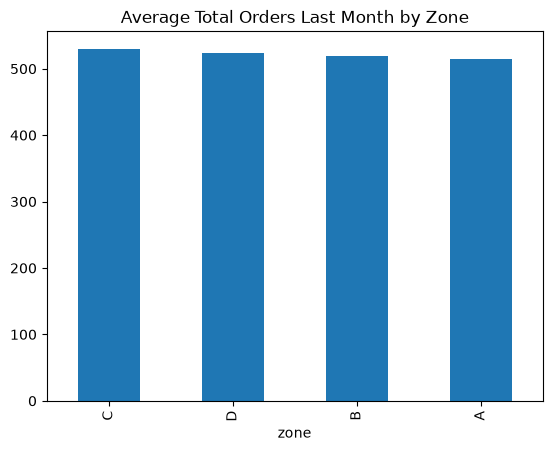

In [20]:
#Visualising it in a bar chart.
df.groupby('zone')['total_orders_last_month'].mean().sort_values(ascending=False).plot(kind='bar', title='Average Total Orders Last Month by Zone')

## Insight: Warehouse Slotting is Misaligned with Order VolumeThe data reveals a clear mismatch between where items are stored and how efficiently they can be picked.


## **The Bottleneck (Zone C):** Zone C has the highest average orders per item (529.98), meaning workers are constantly traveling there to fulfill orders. However, as we saw earlier, it is also the slowest zone in the warehouse. Forcing workers to constantly visit the slowest zone for high-demand items creates a massive, daily delay.   

## **The Workhorse (Zone D):** Zone D handles the highest total volume of orders in the entire warehouse (435,667 total orders). Despite carrying this massive load, it manages to maintain a better picking time than Zone C.   

## **The Opportunity (Zone A):** Zone A is the most efficient picking area, and it successfully handles items with the highest average popularity score (0.55). However, it does not hold the items with the highest average order volumes.   


## **The Root Cause Verdict:**
## The high overall picking time is not caused by workers or layout scores, but by poor inventory slotting. The warehouse is making workers go to the slowest area (Zone C) for the most heavily ordered items. Moving these high-average-order items out of Zone C and into the highly efficient Zone A would drastically reduce the overall time it takes to pick orders.  

In [22]:
# Item Category Bottlenecks (Are certain products harder to pick?)
df.groupby('category')['picking_time_seconds'].mean().sort_values(ascending=False)

category
Apparel        97.081037
Electronics    96.225806
Automotive     95.490881
Pharma         94.889394
Groceries      94.370550
Name: picking_time_seconds, dtype: float64

## The data shows that the type of product being picked clearly impacts how fast a worker can complete the task.   Apparel is the slowest category in the entire warehouse, taking an average of 97.08 seconds per pick.   Groceries are the fastest category to process, averaging 94.37 seconds per pick.   This tells us that the physical nature of clothing—such as dealing with hangers, floppy polybags, or folded items where barcodes are hard to find—is creating a specific bottleneck. You can use this to recommend targeted barcode placement or packaging changes specifically for clothing.

In [24]:
# The "Hidden Variance" (The Human Element)
df.select_dtypes(include="number").corr()["picking_time_seconds"]

stock_level                 -0.029951
reorder_point               -0.015862
reorder_frequency_days      -0.007831
lead_time_days              -0.009673
daily_demand                 0.001171
demand_std_dev               0.032554
item_popularity_score        0.008018
picking_time_seconds         1.000000
handling_cost_per_unit       0.007788
unit_price                  -0.028862
holding_cost_per_unit_day   -0.016677
stockout_count_last_month    0.007227
order_fulfillment_rate       0.023705
total_orders_last_month     -0.009011
turnover_ratio               0.007990
layout_efficiency_score      0.003576
forecasted_demand_next_7d   -0.017191
KPI_score                    0.013927
Name: picking_time_seconds, dtype: float64

## When testing every numerical variable against picking time, every single correlation score is practically zero.   Key factors like stock levels (-0.029), layout efficiency (0.003), and total orders (-0.009) have no mathematical relationship to how long a pick takes.   This is a massive finding because it proves the system and the warehouse environment are not the actual problems.   Since the data variables do not explain the delays, the root cause is human inconsistency. Workers are likely picking the exact same items in completely different ways, which means they are not following a strict Standard Operating Procedure (SOP). This perfectly sets up your Week 4 plan to introduce standardized training and stricter process controls.